# 03 · LGD and EAD
Defaulted loans only. LGD = 1 − recoveries / principal outstanding at default. EAD ratio = principal outstanding / funded amount.

In [1]:
import json, pandas as pd
from IPython.display import Image, display
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
R = '../reports/'; F = R + 'figures/'
res = json.load(open(R + 'results.json'))

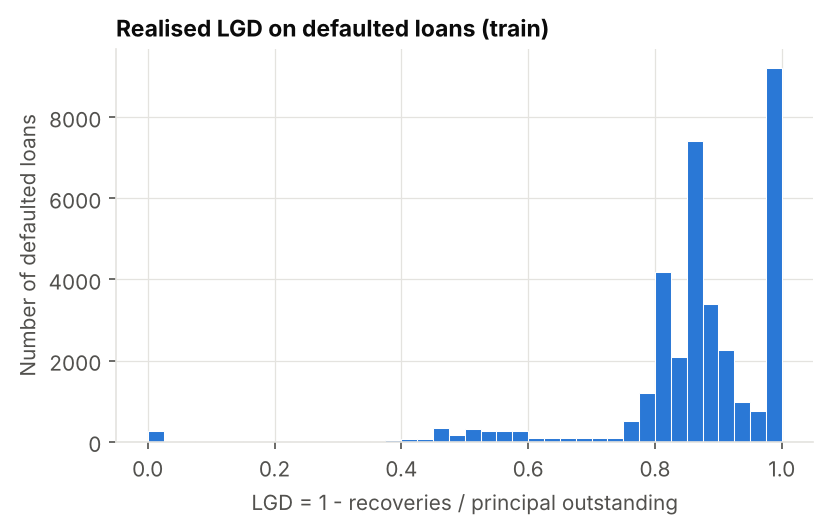

Share with zero recovery: 0.186


In [2]:
display(Image(F + 'lgd_hist.png')); print('Share with zero recovery:', res['lgd']['share_zero_recovery_train'])

In [3]:
pd.DataFrame({(s, m): res['lgd'][s][m] for s in ['train','oot'] for m in ['two_stage','segment_avg','overall_mean']}).T[['n','mean_actual','mean_pred','rmse','mae','r2']]

n  mean_actual  mean_pred      rmse       mae        r2
train two_stage     34693.0     0.867371   0.867373  0.142665  0.088386  0.007602
      segment_avg   34693.0     0.867371   0.867371  0.143141  0.088486  0.000973
      overall_mean  34693.0     0.867371   0.867371  0.143211  0.088646  0.000000
oot   two_stage     42005.0     0.872376   0.867089  0.151463  0.099889  0.000551
      segment_avg   42005.0     0.872376   0.867352  0.151658  0.099484 -0.002027
      overall_mean  42005.0     0.872376   0.867371  0.151587  0.099440 -0.001091

,grade,n,actual_mean,pred_mean
0,A,3795,0.872611,0.867402
1,B,10870,0.873803,0.869746
2,C,15011,0.871219,0.868144
3,D,8549,0.871846,0.865264
4,E,3092,0.874279,0.858386
5,F,575,0.872030,0.861748
6,G,113,0.870513,0.864305


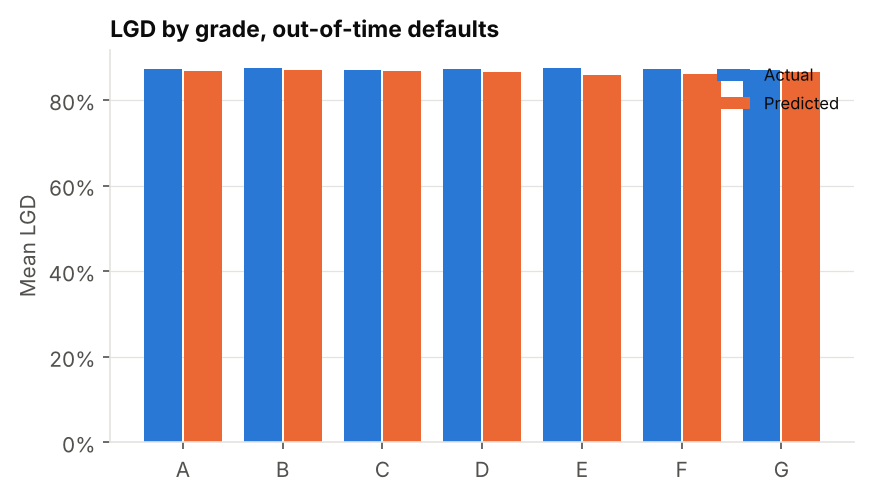

In [4]:
display(pd.read_csv(R + 'lgd_by_grade_oot.csv')); display(Image(F + 'lgd_by_grade.png'))

In [5]:
pd.read_csv(R + 'lgd_coefficients.csv')

,Unnamed: 0,stage1_coef,stage1_p,stage2_coef,stage2_p
0,const,1.159271,9.135331e-89,-1.580466,6.876610e-106
1,log_loan_amnt,0.091263,1.224941e-07,-0.000474,9.810032e-01
2,log_annual_inc,0.161464,1.537017e-17,0.048124,2.359590e-02
3,dti,-0.108904,4.910535e-12,0.020051,2.785531e-01
4,revol_util,0.112339,9.262511e-07,-0.029652,2.634034e-01
5,bc_util,-0.041701,5.896496e-02,0.011143,6.664492e-01
6,acc_open_past_24mths,-0.051986,1.874129e-03,0.007767,6.896222e-01
7,emp_length_yrs,-0.033757,1.967061e-02,-0.001415,9.321777e-01
8,credit_hist_months,-0.117679,1.837681e-16,0.010794,5.377976e-01
9,inq_last_6mths,-0.002507,8.689652e-01,-0.013852,4.261337e-01


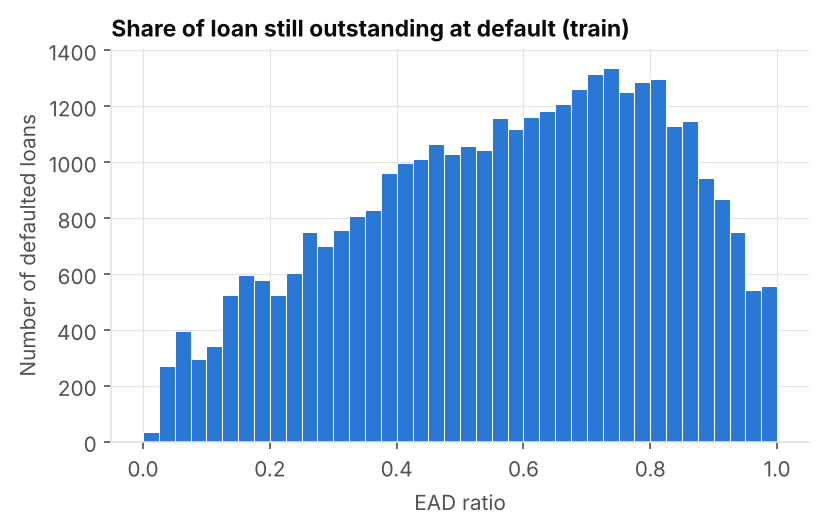

n  mean_actual    mean_pred         rmse          mae        r2
train ratio_model      34693.0     0.573069     0.573069     0.237060     0.198940  0.040982
      ratio_grade_avg  34693.0     0.573069     0.573069     0.238078     0.199989  0.032733
      ead_model        34693.0  6941.282599  6937.425955  3343.231038  2394.874872  0.631825
      ead_grade_avg    34693.0  6941.282599  6926.581637  3360.923797  2409.098675  0.627917
oot   ratio_model      42005.0     0.583617     0.572095     0.231244     0.193306  0.040195
      ratio_grade_avg  42005.0     0.583617     0.571294     0.231682     0.194011  0.036551
      ead_model        42005.0  7298.282385  7118.284471  3351.981871  2371.850014  0.676418
      ead_grade_avg    42005.0  7298.282385  7104.571930  3363.178747  2382.984790  0.674253

In [6]:
display(Image(F + 'ead_ratio_hist.png')); pd.DataFrame({(s, m): res['ead'][s][m] for s in ['train','oot'] for m in res['ead']['oot']}).T[['n','mean_actual','mean_pred','rmse','mae','r2']]

In [7]:
pd.read_csv(R + 'ead_by_grade_oot.csv')

,grade,n,actual_mean,pred_mean
0,A,3795,0.505186,0.491885
1,B,10870,0.539605,0.533779
2,C,15011,0.586611,0.573323
3,D,8549,0.630899,0.615661
4,E,3092,0.662582,0.653245
5,F,575,0.691927,0.686542
6,G,113,0.764734,0.690002
